# Customer Service Chatbot (LangGraph + Gemini)

An agentic AI customer service chatbot. A **router** reads each customer message and sends it to one of three agents:
- **Product agent**: laptop features (searches a product PDF) and prices (looks up a table)
- **Orders agent**: order details and quantity updates
- **Refund agent**: the return and refund policy

Each agent has a system prompt that defines its role, and conversation state is kept across turns with LangGraph's **MemorySaver**.

**To run:** add your Gemini key as a Colab Secret named `GOOGLE_API_KEY` (key icon in the sidebar, Notebook access on), restart the session once after the install cell, then run the cells in order.

In [1]:
# Install the packages the project needs (restart the session once after this runs)
!pip install -U "langchain-google-genai<4" langchain-core langgraph langchain-community langchain-chroma pypdf pandas

In [2]:
# Connect to Gemini. The API key is read from Colab Secrets, never typed into the code.
# `model` is the chat model; `embedding` turns text into vectors for searching the product PDF.
import os
from google.colab import userdata
os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")

from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
model = ChatGoogleGenerativeAI(model="gemini-2.5-flash", temperature=0)
embedding = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")

In [3]:
# Download the course repo so the notebook can read its data files (prices, orders, product PDF)
!git clone https://github.com/myrah/build-ai-agents-and-chatbots-with-langgraph-2021112.git
%cd build-ai-agents-and-chatbots-with-langgraph-2021112

Cloning into 'build-ai-agents-and-chatbots-with-langgraph-2021112'...
remote: Enumerating objects: 84, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 84 (delta 26), reused 11 (delta 11), pack-reused 50 (from 1)
Receiving objects: 100% (84/84), 204.99 KiB | 2.70 MiB/s, done.
Resolving deltas: 100% (31/31), done.
/content/build-ai-agents-and-chatbots-with-langgraph-2021112


In [4]:
# Helper: Gemini sometimes returns a reply as a list of parts; this turns any reply into plain text
def msg_text(m):
    c = m.content
    if isinstance(c, list):
        return "".join(p.get("text", "") if isinstance(p, dict) else str(p) for p in c)
    return c

### PRODUCT AGENT

In [5]:
# Product agent, tool 1: look up a laptop's price from the pricing table
import pandas as pd
from langchain_core.tools import tool

#Load the laptop product pricing CSV into a Pandas dataframe.
product_pricing_df = pd.read_csv("data/Laptop pricing.csv")
print(product_pricing_df)

@tool
def get_laptop_price(laptop_name:str) -> int :
    """
    This function returns the price of a laptop, given its name as input.
    It performs a substring match between the input name and the laptop name.
    If a match is found, it returns the pricxe of the laptop.
    If there is NO match found, it returns -1
    """

    #Filter Dataframe for matching names
    match_records_df = product_pricing_df[
                        product_pricing_df["Name"].str.contains(
                                                "^" + laptop_name, case=False)
                        ]
    #Check if a record was found, if not return -1
    if len(match_records_df) == 0 :
        return -1
    else:
        return match_records_df["Price"].iloc[0]

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


            Name  Price  ShippingDays
0  AlphaBook Pro   1499             2
1     GammaAir X   1399             7
2  SpectraBook S   2499             7
3   OmegaPro G17   2199            14
4  NanoEdge Flex   1699             2


In [6]:
# Product agent, tool 2: index the product PDF so the agent can search laptop features
# CHANGED: removed the 3 pysqlite3 lines (only needed in the course's Codespaces)
# CHANGED: create_retriever_tool now comes from langchain_core
from langchain_core.tools import create_retriever_tool
from langchain_chroma import Chroma
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Load, chunk and index the contents of the product featuers document.
loader=PyPDFLoader("./data/Laptop product descriptions.pdf")
docs = loader.load()

text_splitter = RecursiveCharacterTextSplitter(chunk_size=1024, chunk_overlap=256)
splits = text_splitter.split_documents(docs)

#Create a vector store with Chroma
prod_feature_store = Chroma.from_documents(
    documents=splits,
    embedding=embedding
)

get_product_features = create_retriever_tool(
    prod_feature_store.as_retriever(search_kwargs={"k": 1}),
    name="Get_Product_Features",
    description="""
    This store contains details about Laptops. It lists the available laptops
    and their features including CPU, memory, storage, design and advantages
    """
)

/tmp/ipykernel_3170/2088299967.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [7]:
# Product agent: system prompt (role) + two tools + MemorySaver for conversation memory
from langgraph.prebuilt import create_react_agent
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import AIMessage,HumanMessage,SystemMessage

#Create a System prompt to provide a persona to the chatbot
system_prompt = SystemMessage("""
    You are professional chatbot that answers questions about laptops sold by your company.
    To answer questions about laptops, you will ONLY use the available tools and NOT your own memory.
    When using Get_Product_Features, search with ONLY the laptop's name (for example "GammaAir"), nothing else.
    Answer in a short, friendly paragraph. Do not copy the document's formatting.
    You will handle small talk and greetings by producing professional responses.
    """
)

#Create a list of tools available
tools = [get_laptop_price, get_product_features]

#Create memory across questions in a conversation (conversation memory)
checkpointer=MemorySaver()

#Create a Product QnA Agent. This is actual a graph in langGraph
product_QnA_agent=create_react_agent(
                                model=model, #LLM to use
                                tools=tools, #List of tools to use
                                prompt=system_prompt, # CHANGED: was state_modifier=
                                debug=False, #Debugging turned on if needed
                                checkpointer=checkpointer #For conversation memory
)

/tmp/ipykernel_3170/4179988118.py:23: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  product_QnA_agent=create_react_agent(


In [8]:
# Test: one product question (shows the agent calling its tools)
import uuid
#To maintain memory, each request should be in the context of a thread.
#Each user conversation will use a separate thread ID
config = {"configurable": {"thread_id": str(uuid.uuid4())}}  # CHANGED: wrapped in str()

#Test the agent with an input
inputs = {"messages":[
                HumanMessage("What are the features and pricing for GammaAir?")
            ]}

#Use streaming to print responses as the agent does the work.
for stream in product_QnA_agent.stream(inputs, config, stream_mode="values"):
    message=stream["messages"][-1]
    if isinstance(message, tuple):
        print(message)
    else:
        message.pretty_print()

================================ Human Message =================================

What are the features and pricing for GammaAir?
================================== Ai Message ==================================
Tool Calls:
  Get_Product_Features (1b15dd85-7bab-40c6-9ab3-0eb3babc5a50)
 Call ID: 1b15dd85-7bab-40c6-9ab3-0eb3babc5a50
  Args:
    query: GammaAir
  get_laptop_price (bc99ba12-1c61-4e5d-9d90-8db4fbc59272)
 Call ID: bc99ba12-1c61-4e5d-9d90-8db4fbc59272
  Args:
    laptop_name: GammaAir
================================= Tool Message =================================
Name: get_laptop_price

1399
================================== Ai Message ==================================

[{'type': 'text', 'text': 'The GammaAir X features an AMD Ryzen 7 processor, 32GB of DDR4 memory, and a 512GB NVMe SSD, all in a thin and light design for excellent portability and high performance. It is priced at $1399.', 'extras': {'signature': 'CocDAWkUfRP3SkOW8fF5k2z9jQsL12+I73fr8Mzi8Oiad7lXiLbrpPKvYWL4

In [9]:
# Test: a multi-turn product conversation (the agent remembers earlier turns)
import uuid
#Send a sequence of messages to chatbot and get its response
#This simulates the conversation between the user and the Agentic chatbot
user_inputs = [
    "Hello",
    "I am looking to buy a laptop",
    "Give me a list of available laptop names",
    "Tell me about the features of  SpectraBook",
    "How much does it cost?",
    "Give me similar information about OmegaPro",
    "What info do you have on AcmeRight ?",
    "Thanks for the help"
]

#Create a new thread
config = {"configurable": {"thread_id": str(uuid.uuid4())}}

for input in user_inputs:
    print(f"----------------------------------------\nUSER : {input}")
    #Format the user message
    user_message = {"messages":[HumanMessage(input)]}
    #Get response from the agent
    ai_response = product_QnA_agent.invoke(user_message,config=config)
    #Print the response
    print(f"AGENT : {msg_text(ai_response['messages'][-1])}")

----------------------------------------
USER : Hello
AGENT : Hello! I'm here to help you with any questions you have about our laptops.
----------------------------------------
USER : I am looking to buy a laptop
AGENT : That's great! Do you have a particular model in mind, or are you looking for recommendations based on certain features?
----------------------------------------
USER : Give me a list of available laptop names
AGENT : We have several laptops available: AlphaBook Pro, GammaAir X, SpectraBook S, OmegaPro G17, and NanoEdge Flex.
----------------------------------------
USER : Tell me about the features of  SpectraBook
AGENT : The SpectraBook S is designed for power users, featuring an Intel Core i9 processor, 64GB RAM, and a massive 2TB SSD. This workstation-class laptop is perfect for intensive tasks like video editing and 3D rendering.
----------------------------------------
USER : How much does it cost?
AGENT : The SpectraBook S costs $2499.
--------------------------

In [10]:
# Test: two users with separate threads each keep their own conversation memory
#conversation memory by user
def execute_prompt(user, config, prompt):
    inputs = {"messages":[("user",prompt)]}
    ai_response = product_QnA_agent.invoke(inputs,config=config)
    print(f"\n{user}: {msg_text(ai_response['messages'][-1])}")

#Create different session threads for 2 users
config_1 = {"configurable": {"thread_id": str(uuid.uuid4())}}
config_2 = {"configurable": {"thread_id": str(uuid.uuid4())}}

#Test both threads
execute_prompt("USER 1", config_1, "Tell me about the features of  SpectraBook")
execute_prompt("USER 2", config_2, "Tell me about the features of  GammaAir")
execute_prompt("USER 1", config_1, "What is its price ?")
execute_prompt("USER 2", config_2, "What is its price ?")


USER 1: The SpectraBook S is a powerful laptop designed for intensive tasks like video editing and 3D rendering. It features an Intel Core i9 processor, 64GB of RAM, and a massive 2TB SSD.

USER 2: The GammaAir X is a fantastic choice for those seeking high performance in a portable design! It features an AMD Ryzen 7 processor, 32GB of DDR4 memory, and a speedy 512GB NVMe SSD, all packed into a thin and light form factor.

USER 1: The SpectraBook S is priced at $2499.

USER 2: The GammaAir X is priced at $1399.


### ORDER AGENT


In [11]:
# Orders agent: load the orders table
import pandas as pd

#Load the laptop product orders CSV into a Pandas dataframe.
product_orders_df = pd.read_csv("data/Laptop Orders.csv")
print(product_orders_df)

   Order ID Product Ordered  Quantity Ordered Delivery Date
0  ORD-8276   SpectraBook S                 3    2024-10-16
1  ORD-6948    OmegaPro G17                 3    2024-10-25
2  ORD-7311   NanoEdge Flex                 2    2024-10-19
3  ORD-4633    OmegaPro G17                 2    2024-10-15
4  ORD-2050      GammaAir X                 2    2024-10-26


In [12]:
# Orders agent tools: look up an order and update its quantity
from langchain_core.tools import tool

@tool
def get_order_details(order_id:str) -> str :
    """
    This function returns details about a laptop order, given an order ID
    It performs an exact match between the input order id and available order ids
    If a match is found, it returns products (laptops) ordered, quantity ordered and delivery date.
    If there is NO match found, it returns -1
    """
    #Filter Dataframe for order ID
    match_order_df = product_orders_df[
                        product_orders_df["Order ID"] == order_id ]

    #Check if a record was found, if not return -1
    if len(match_order_df) == 0 :
        return -1
    else:
        return match_order_df.iloc[0].to_dict()

@tool
def update_quantity(order_id:str, new_quantity:int) -> bool :
    """
    This function updates the quantity of products ( laptops ) ordered for a given order Id.
    It there are no matching orders, it returns False.
    """
    #Find if matching record exists
    match_order_df = product_orders_df[
                        product_orders_df["Order ID"] == order_id ]

    #Check if a record was found, if not return -1
    if len(match_order_df) == 0 :
        return -1
    else:
        product_orders_df.loc[
            product_orders_df["Order ID"] == order_id,
                "Quantity Ordered"] = new_quantity
        return True

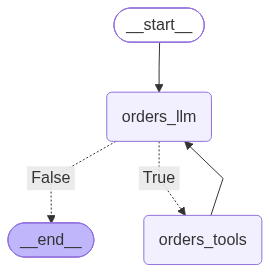

In [13]:
# Orders agent: a custom LangGraph agent (model <-> tools loop) with MemorySaver memory
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver
from typing import TypedDict, Annotated
import operator
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage
from IPython.display import Image
import json

#An Agent State class that keep state of the agent while it answers a query
class OrdersAgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]

#-----------------------------------------------------------------------------
#An agent class that manages all agentic interactions
class OrdersAgent:

    #Setup the agent graph, tools and memory
    def __init__(self, model, tools, system_prompt, debug):

        self.system_prompt=system_prompt
        self.debug=debug

        #Setup the graph for the agent manually
        agent_graph=StateGraph(OrdersAgentState)
        agent_graph.add_node("orders_llm",self.call_llm)
        agent_graph.add_node("orders_tools",self.call_tools)
        agent_graph.add_conditional_edges(
            "orders_llm",
            self.is_tool_call,
            {True: "orders_tools", False: END }
        )
        agent_graph.add_edge("orders_tools","orders_llm")
        #Set where there graph starts
        agent_graph.set_entry_point("orders_llm")

        #Add chat memory
        self.memory=MemorySaver()
        #compile the graph
        self.agent_graph = agent_graph.compile(checkpointer=self.memory)

        #Setup tools
        self.tools = { tool.name : tool for tool in tools }
        if self.debug:
            print("\nTools loaded :", self.tools)

        #attach tools to model
        self.model=model.bind_tools(tools)


    #Call the LLM with the messages to get next action/result
    def call_llm(self, state:OrdersAgentState):

        messages=state["messages"]

        #If system prompt exists, add to messages in the front
        if self.system_prompt:
            messages = [SystemMessage(content=self.system_prompt)] + messages

        #invoke the model with the message history
        result = self.model.invoke(messages)
        if self.debug:
            print(f"\nLLM Returned : {result}")
        #Return the LLM output
        return { "messages":[result] }


    #Check if the next action is a tool call.
    def is_tool_call(self, state:OrdersAgentState):
        last_message = state["messages"][-1]
        #If tool action is requested
        if len(last_message.tool_calls) > 0 :
            return True
        else:
            return False

    #Execute the tool requested with the given parameters
    def call_tools(self, state:OrdersAgentState):
        #Get last message
        tool_calls = state["messages"][-1].tool_calls
        results=[]

        #Multiple tool calls may be requested. Execute one by one
        for tool in tool_calls:
            #Handle tool missing error
            if not tool["name"] in self.tools:
                print(f"Unknown tool name {tool}")
                result = "Invalid tool found. Please retry"
            else:
                #Call the tool and collect results
                result=self.tools[tool["name"]].invoke(tool["args"])

            #append results to the list of tool results
            results.append(ToolMessage(tool_call_id=tool['id'],
                                       name=tool['name'],
                                       content=str(result)))

            if self.debug:
                print(f"\nTools returned {results}")
        # CHANGED: moved this return out of the loop (the starter returns inside it,
        # so only the first tool call gets answered, which can break if the model
        # asks for two tools at once)
        return { "messages" : results }

#-----------------------------------------------------------------------------
#Setup the custom agent

#Note that this is a string, since the model init only accepts a string.
system_prompt = """
    You are professional chatbot that manages orders for laptops sold by our company.
    The tools allow for retrieving order details as well as update order quantity.
    Order IDs look like ORD-7311. Always pass the full order ID exactly as the user wrote it, including the ORD- prefix.
    Do NOT reveal information about other orders than the one requested.
    You will handle small talk and greetings by producing professional responses.
    """

#Create the custom orders agent
orders_agent = OrdersAgent(model,
                           [get_order_details, update_quantity],
                           system_prompt,
                           debug=False)

#Visualize the Agent
Image(orders_agent.agent_graph.get_graph().draw_mermaid_png())

In [14]:
# Test: one order lookup
import uuid
config = {"configurable": {"thread_id": str(uuid.uuid4())}}
r = orders_agent.agent_graph.invoke({"messages":[HumanMessage("Please show me the details of the order ORD-7311")]}, config=config)
print(msg_text(r['messages'][-1]))

Here are the details for order ORD-7311:

Product Ordered: NanoEdge Flex
Quantity Ordered: 2
Delivery Date: 2024-10-19


In [15]:
# Test: a multi-turn order conversation (lookup, update quantity, unknown order, goodbye)
import uuid
#Send a sequence of messages to chatbot and get its response
#This simulates the conversation between the user and the Agentic chatbot
user_inputs = [
    "How are you doing?",
    "Please show me the details of the order ORD-7311",
    "Can you add one more of that laptop to the order? ",
    "Can you show me the details again ? ",
    "What about order ORD-9999 ?",
    "Bye"
]

#Create a new thread
config = {"configurable": {"thread_id": str(uuid.uuid4())}}

for input in user_inputs:
    print(f"----------------------------------------\nUSER : {input}")
    #Format the user message
    user_message = {"messages":[HumanMessage(input)]}
    #Get response from the agent
    ai_response = orders_agent.agent_graph.invoke(user_message,config=config)
    #Print the response
    print(f"\nAGENT : {msg_text(ai_response['messages'][-1])}")

----------------------------------------
USER : How are you doing?

AGENT : I'm doing well, thank you for asking! I'm ready to assist you with any laptop order inquiries you may have.
----------------------------------------
USER : Please show me the details of the order ORD-7311

AGENT : Here are the details for order ORD-7311:

Product Ordered: NanoEdge Flex
Quantity Ordered: 2
Delivery Date: 2024-10-19
----------------------------------------
USER : Can you add one more of that laptop to the order? 

AGENT : I have updated the quantity for order ORD-7311 to 3.
----------------------------------------
USER : Can you show me the details again ? 

AGENT : Here are the updated details for order ORD-7311:

Product Ordered: NanoEdge Flex
Quantity Ordered: 3
Delivery Date: 2024-10-19
----------------------------------------
USER : What about order ORD-9999 ?

AGENT : I'm sorry, but I cannot find any details for order ORD-9999. Please double-check the order ID and try again.
---------------

### REFUND AGENT

In [16]:
# Refund agent: answers only from the refund policy written in its system prompt (no tools needed)
from langgraph.prebuilt import create_react_agent
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import SystemMessage

refund_prompt = SystemMessage("""
    You are a professional chatbot that answers questions about the refund and return policy
    for laptops sold by our company. Use ONLY this policy:
    - Laptops can be returned within 30 days of delivery if unused and in original packaging.
    - A receipt or order ID is required for any refund.
    - Refunds are issued to the original payment method within 5-7 business days.
    - Opened or damaged-by-user laptops are eligible for exchange only.
    If asked about something outside this policy, say you don't have that information.
    You will handle small talk and greetings by producing professional responses.
    """)

refund_agent = create_react_agent(
    model=model,
    tools=[],                      # the policy is in the prompt, so no tools are needed
    prompt=refund_prompt,
    checkpointer=MemorySaver()     # conversation memory
)

/tmp/ipykernel_3170/3784536194.py:17: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  refund_agent = create_react_agent(


### ROUTER AGENT
The router picks the right agent for each message. Each agent keeps its own conversation memory.

In [17]:
# Wrap each agent as a node the router can call.
# Each agent gets only the user's latest message, and keeps its own memory by thread_id.
import functools
from langchain_core.messages import AIMessage, HumanMessage

# Helper function to invoke an agent
def agent_node(state, agent, name, config):
    thread_id = config["configurable"]["thread_id"]
    agent_config = {"configurable": {"thread_id": thread_id}}

    # CHANGED: send only the user's latest message (not the router's one-word answer)
    last_user_msg = [m for m in state["messages"] if isinstance(m, HumanMessage)][-1]

    result = agent.invoke({"messages": [last_user_msg]}, agent_config)

    final_result = AIMessage(msg_text(result['messages'][-1]))   # msg_text handles Gemini's list replies
    return {"messages": [final_result]}

#Create the product QnA node
product_QnA_node = functools.partial(agent_node, agent=product_QnA_agent, name="Product_QnA_Agent")
#Create the Orders node (a custom agent, so we pass its graph)
orders_node = functools.partial(agent_node, agent=orders_agent.agent_graph, name="Orders_Agent")
#Create the Refund node
refund_node = functools.partial(agent_node, agent=refund_agent, name="Refund_Agent")

In [18]:
# Router: one LLM call picks PRODUCT, ORDER, REFUND, SMALLTALK or END, then the graph sends the message to that agent
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, END
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage
import operator

class RouterAgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]

class RouterAgent:

    def __init__(self, model, system_prompt, smalltalk_prompt, debug=False):

        self.system_prompt=system_prompt
        self.smalltalk_prompt=smalltalk_prompt
        self.model=model
        self.debug=debug

        router_graph=StateGraph(RouterAgentState)
        router_graph.add_node("Router",self.call_llm)
        router_graph.add_node("Product_Agent",product_QnA_node)
        router_graph.add_node("Orders_Agent",orders_node)
        router_graph.add_node("Refund_Agent",refund_node)          # CHANGED: new agent
        router_graph.add_node("Small_Talk", self.respond_smalltalk)

        router_graph.add_conditional_edges(
            "Router",
            self.find_route,
            {"PRODUCT": "Product_Agent",
             "ORDER" : "Orders_Agent",
             "REFUND" : "Refund_Agent",                             # CHANGED: new route
             "SMALLTALK" : "Small_Talk",
             "END": END }
        )

        #One way routing, not coming back to router
        router_graph.add_edge("Product_Agent",END)
        router_graph.add_edge("Orders_Agent",END)
        router_graph.add_edge("Refund_Agent",END)                   # CHANGED
        router_graph.add_edge("Small_Talk",END)

        #Set where there graph starts
        router_graph.set_entry_point("Router")
        self.router_graph = router_graph.compile()

    def call_llm(self, state:RouterAgentState):
        messages=state["messages"]
        if self.debug:
            print(f"Call LLM received {messages}")

        #If system prompt exists, add to messages in the front
        if self.system_prompt:
            messages = [SystemMessage(content=self.system_prompt)] + messages

        #invoke the model with the message history
        result = self.model.invoke(messages)

        if self.debug:
            print(f"Call LLM result {result}")
        return { "messages":[result] }

    def respond_smalltalk(self, state:RouterAgentState):
        messages=state["messages"]
        if self.debug:
            print(f"Small talk received: {messages}")

        messages = [SystemMessage(content=self.smalltalk_prompt)] + messages
        result = self.model.invoke(messages)

        if self.debug:
            print(f"Small talk result {result}")
        return { "messages":[result] }

    def find_route(self, state:RouterAgentState):
        last_message = state["messages"][-1]
        if self.debug:
            print("Router: Last result from LLM : ", last_message)

        # CHANGED: clean up the text so "ORDER\n" or "order" still match
        destination = msg_text(last_message).strip().upper()

        if self.debug:
            print(f"Destination chosen : {destination}")
        return destination

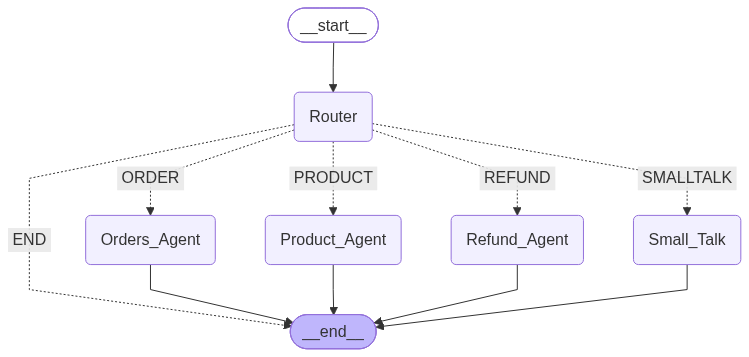

In [19]:
# System prompts that define the router's role and the small-talk role, then build the router
from IPython.display import Image

#Setup the system prompt for the router (CHANGED: added REFUND)
router_system_prompt = """
You are a Router, that analyzes the input query and chooses 5 options:
SMALLTALK: If the user input is small talk, like greetings and good byes.
PRODUCT: If the query is a product question about laptops, like features, specifications and pricing.
ORDER: If the query is about orders for laptops, like order status, order details or update order quantity.
REFUND: If the query is about refunds, returns or the return policy.
END: Default, when its none of the above.

The output should only be just one word out of the possible 5 : SMALLTALK, PRODUCT, ORDER, REFUND, END.
"""

smalltalk_prompt="""
If the user request is small talk, like greetings and goodbyes, respond professionally.
Mention that you will be able to answer questions about laptop product features, provide order status and updates, and explain the refund policy.
"""

router_agent = RouterAgent(model,
                           router_system_prompt,
                           smalltalk_prompt,
                           debug=False)

Image(router_agent.router_graph.get_graph().draw_mermaid_png())

In [20]:
# Final demo: order, refund, product, and a follow-up question that needs memory
import uuid
#Send a sequence of messages to the chatbot (covers order, refund, product, and a follow-up that needs memory)
user_inputs = [
    "Please show me the details of the order ORD-7311",
    "What is your refund policy?",
    "Tell me about the features of GammaAir laptop",
    "How much does it cost?"
]

#Create a new thread (one thread = one conversation, so the agents remember)
config = {"configurable": {"thread_id": str(uuid.uuid4())}}

for input in user_inputs:
    print(f"----------------------------------------\nUSER : {input}")
    user_message = {"messages":[HumanMessage(input)]}
    ai_response = router_agent.router_graph.invoke(user_message,config=config)
    print(f"\nAGENT : {msg_text(ai_response['messages'][-1])}")

----------------------------------------
USER : Please show me the details of the order ORD-7311

AGENT : Here are the details for order ORD-7311:

Product Ordered: NanoEdge Flex
Quantity Ordered: 3
Delivery Date: 2024-10-19
----------------------------------------
USER : What is your refund policy?

AGENT : Our refund policy for laptops is as follows:

*   Laptops can be returned for a refund within 30 days of delivery, provided they are unused and in their original packaging.
*   A receipt or order ID is required to process any refund.
*   Refunds are issued to the original payment method within 5-7 business days.
*   Please note that opened or user-damaged laptops are eligible for exchange only, not a refund.
----------------------------------------
USER : Tell me about the features of GammaAir laptop

AGENT : The GammaAir X laptop is a great choice for those seeking high performance in a portable design! It features an AMD Ryzen 7 processor, 32GB of DDR4 memory, and a 512GB NVMe SS